<a href="https://colab.research.google.com/github/Truthwhyte/fashion-review-classifier/blob/main/fashion_review_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Will they recommend it? Spotting unhappy fashion shoppers from review text

**Question.** An online clothing retailer gets thousands of reviews. Can we automatically flag the reviews whose writer would *not* recommend the item, so the merchandising team sees problems (bad sizing, poor fabric) early?

**Data.** 22,641 women's clothing reviews from an e-commerce retailer ([Hugging Face: `saattrupdan/womens-clothing-ecommerce-reviews`](https://huggingface.co/datasets/saattrupdan/womens-clothing-ecommerce-reviews)). Each review has free text and a `recommended_ind` flag (1 = would recommend).

**Approach.** Three models, judged on the same held-out test set:

1. **Baseline:** TF-IDF features + logistic regression (scikit-learn)
2. **Fine-tuned transformer:** DistilBERT trained with a hand-written PyTorch training loop
3. **Zero-shot foundation model:** BART-MNLI with no training at all, to see how far a pre-trained model gets on its own

**Why these metrics.** Only about 18% of reviews are "not recommended", so accuracy is misleading (always guessing "recommended" scores ~82%). I report precision, recall and F1 for the *not recommended* class, plus PR-AUC.

**How to run.** Open in Google Colab → *Runtime → Change runtime type → T4 GPU* → *Runtime → Run all*. It takes about 10–15 minutes.

## 1. Setup

In [ ]:
!pip install -q datasets

In [ ]:
import os, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             precision_recall_curve)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 2. Load and clean the data

In [ ]:
from datasets import load_dataset

raw = load_dataset("saattrupdan/womens-clothing-ecommerce-reviews", split="train").to_pandas()
print("Raw rows:", len(raw))

df = raw.copy()
df["review_text"] = df["review_text"].fillna("").str.strip()
df = df[df["review_text"].str.len() > 0]            # drop empty reviews
df = df.drop_duplicates(subset="review_text")         # drop exact duplicate texts
df["not_recommended"] = (df["recommended_ind"] == 0).astype(int)   # positive class = unhappy shopper
df["n_words"] = df["review_text"].str.split().str.len()
df = df.reset_index(drop=True)

print("Clean rows:", len(df))
print(df["not_recommended"].value_counts(normalize=True).rename({0: "recommended", 1: "not recommended"}).round(3))
df.head(3)

README.md:   0%|          | 0.00/1.01k [00:00<?, ?B/s]

data/train-00000-of-00001-44ddebcb331919(…): reconstructing file:   0%|          |  0.00B / 3.97MB            

data/train-00000-of-00001-44ddebcb331919(…): downloading bytes:           |  0.00B            

data/test-00000-of-00001-90b9c3d0edf6fc3(…): reconstructing file:   0%|          |  0.00B /  192kB            

data/test-00000-of-00001-90b9c3d0edf6fc3(…): downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/20641 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Generating val split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Raw rows: 20641
Clean rows: 20636
not_recommended
recommended        0.819
not recommended    0.181
Name: proportion, dtype: float64


,review_text,age,rating,positive_feedback_count,division_name,department_name,class_name,recommended_ind,not_recommended,n_words
0,I loved this shirt until the first time i wash...,39,1,0,General,Tops,Knits,0,1,36
1,"This sweater was unflattering me, very boxy an...",44,3,0,General,Tops,Sweaters,0,1,27
2,I fell in love with these bottoms at first sit...,41,5,2,General,Bottoms,Pants,1,0,93


## 3. Explore

Note: `rating` is almost a copy of the label (people who give 1–2 stars rarely recommend), so I **don't use it as a feature**. The point is to learn from the text alone, which is what a team would have for reviews on other platforms.

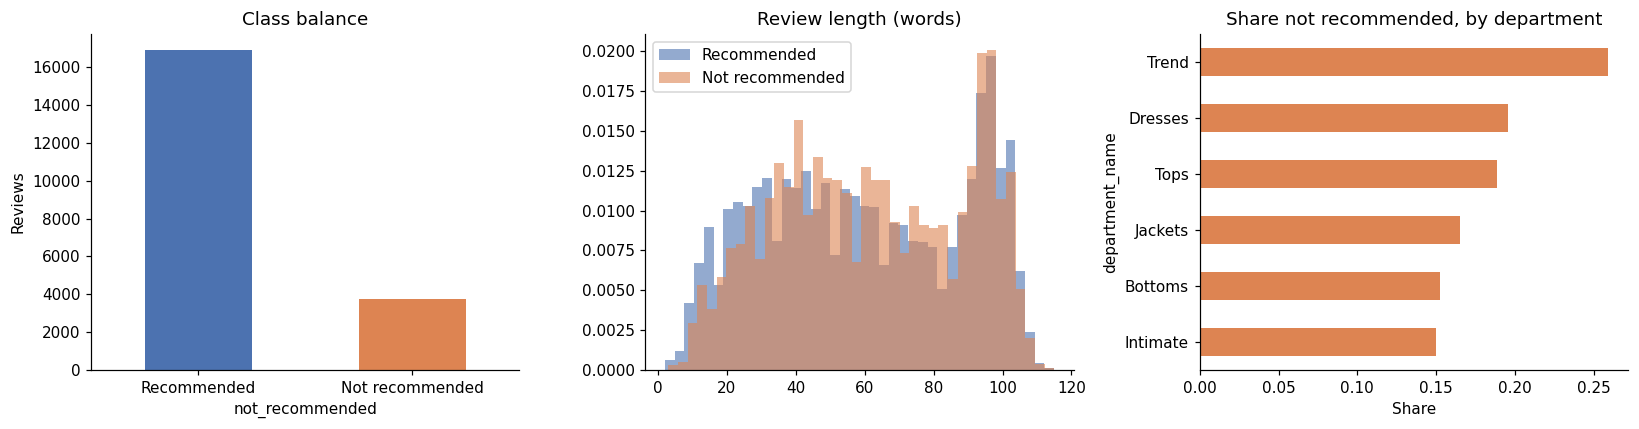

not_recommended  recommended  not recommended
rating                                       
1                       0.01             0.99
2                       0.06             0.94
3                       0.42             0.58
4                       0.97             0.03
5                       1.00             0.00


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df["not_recommended"].map({0: "Recommended", 1: "Not recommended"}).value_counts().plot.bar(ax=axes[0], color=["#4C72B0", "#DD8452"])
axes[0].set_title("Class balance"); axes[0].set_ylabel("Reviews"); axes[0].tick_params(axis="x", rotation=0)

for label, colour in [(0, "#4C72B0"), (1, "#DD8452")]:
    axes[1].hist(df.loc[df["not_recommended"] == label, "n_words"], bins=40, alpha=0.6, color=colour,
                 label="Not recommended" if label else "Recommended", density=True)
axes[1].set_title("Review length (words)"); axes[1].legend()

rate = df.groupby("department_name")["not_recommended"].mean().sort_values()
rate.plot.barh(ax=axes[2], color="#DD8452")
axes[2].set_title("Share not recommended, by department"); axes[2].set_xlabel("Share")

plt.tight_layout(); plt.savefig("figures/eda.png", bbox_inches="tight"); plt.show()

print(pd.crosstab(df["rating"], df["not_recommended"], normalize="index").round(2).rename(columns={0: "recommended", 1: "not recommended"}))

## 4. Train / validation / test split

Stratified 70 / 15 / 15 so every split keeps the same share of unhappy shoppers. The **test set is only used once per model**, at the end; choices (regularisation strength, decision threshold, best epoch) are made on validation.

In [ ]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["not_recommended"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["not_recommended"], random_state=SEED)
for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s} {len(part):6d} rows, {part['not_recommended'].mean():.3f} not recommended")

y_train, y_val, y_test = (part["not_recommended"].values for part in (train_df, val_df, test_df))

train  14445 rows, 0.181 not recommended
val     3095 rows, 0.181 not recommended
test    3096 rows, 0.181 not recommended


### Evaluation helpers

Every model outputs a probability that the shopper would *not* recommend. I pick the threshold that maximises F1 on validation, then apply that same threshold to test.

In [ ]:
def best_threshold(y_true, probs):
    precision, recall, thresholds = precision_recall_curve(y_true, probs)
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-9, None)
    return float(thresholds[np.argmax(f1[:-1])])

def evaluate(y_true, probs, threshold):
    preds = (probs >= threshold).astype(int)
    return {
        "threshold": round(threshold, 3),
        "accuracy": accuracy_score(y_true, preds),
        "precision": precision_score(y_true, preds, zero_division=0),
        "recall": recall_score(y_true, preds),
        "f1": f1_score(y_true, preds),
        "roc_auc": roc_auc_score(y_true, probs),
        "pr_auc": average_precision_score(y_true, probs),
    }

results = {}        # model name -> test metrics
test_probs = {}     # model name -> test probabilities

## 5. Baseline: TF-IDF + logistic regression

In [ ]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50_000, sublinear_tf=True)
X_train = vectorizer.fit_transform(train_df["review_text"])
X_val = vectorizer.transform(val_df["review_text"])
X_test = vectorizer.transform(test_df["review_text"])

# choose regularisation strength C on validation PR-AUC
best = None
for C in [0.25, 1.0, 4.0]:
    clf = LogisticRegression(C=C, class_weight="balanced", max_iter=2000)
    clf.fit(X_train, y_train)
    score = average_precision_score(y_val, clf.predict_proba(X_val)[:, 1])
    print(f"C={C:<5} validation PR-AUC={score:.3f}")
    if best is None or score > best[0]:
        best = (score, C, clf)

_, best_C, logreg = best
val_p = logreg.predict_proba(X_val)[:, 1]
thr = best_threshold(y_val, val_p)
test_probs["TF-IDF + LogReg"] = logreg.predict_proba(X_test)[:, 1]
results["TF-IDF + LogReg"] = evaluate(y_test, test_probs["TF-IDF + LogReg"], thr)
print(f"Chosen C={best_C}, threshold={thr:.3f}")
pd.Series(results["TF-IDF + LogReg"]).round(3)

C=0.25  validation PR-AUC=0.725
C=1.0   validation PR-AUC=0.753
C=4.0   validation PR-AUC=0.771
Chosen C=4.0, threshold=0.510


,0
threshold,0.510
accuracy,0.902
precision,0.705
recall,0.790
f1,0.745
roc_auc,0.946
pr_auc,0.810


**What the baseline learned.** The largest coefficients show which words and phrases push a review towards *not recommended* and which push it away. This is a quick sanity check that the model learned something sensible.

In [ ]:
terms = np.array(vectorizer.get_feature_names_out())
coefs = logreg.coef_[0]
order = np.argsort(coefs)
pd.DataFrame({"pushes towards NOT recommended": terms[order[::-1][:15]],
              "pushes towards recommended": terms[order[:15]]})

,pushes towards NOT recommended,pushes towards recommended
0,to love,love
1,disappointed,perfect
2,not flattering,great
3,unflattering,little
4,cheap,with
5,was,comfortable
6,going back,not too
7,returning,soft
8,back,fits
9,huge,love this


## 6. Fine-tuned transformer: DistilBERT with a PyTorch training loop

Instead of a high-level `Trainer`, the loop below is written out in PyTorch so every step is visible: tokenise, batch, forward pass, class-weighted loss, backward pass, optimiser and learning-rate schedule, then validation after each epoch, keeping the best epoch.

In [ ]:
import copy
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from tqdm.auto import tqdm

torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

MODEL_NAME = "distilbert-base-uncased"
MAX_LEN, BATCH, EPOCHS, LR = 128, 32, 2, 2e-5
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class ReviewDataset(Dataset):
    def __init__(self, texts, labels):
        self.enc = tokenizer(list(texts), truncation=True, max_length=MAX_LEN, padding="max_length", return_tensors="pt")
        self.labels = torch.tensor(labels, dtype=torch.long)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        return {"input_ids": self.enc["input_ids"][i], "attention_mask": self.enc["attention_mask"][i], "labels": self.labels[i]}

train_loader = DataLoader(ReviewDataset(train_df["review_text"], y_train), batch_size=BATCH, shuffle=True)
val_loader = DataLoader(ReviewDataset(val_df["review_text"], y_val), batch_size=BATCH * 2)
test_loader = DataLoader(ReviewDataset(test_df["review_text"], y_test), batch_size=BATCH * 2)

Device: cuda


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(device)

# weight the rare class more heavily so the model doesn't just predict "recommended"
class_weights = torch.tensor(len(y_train) / (2 * np.bincount(y_train)), dtype=torch.float, device=device)
loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

@torch.no_grad()
def predict_probs(loader):
    model.eval()
    out = []
    for batch in loader:
        with torch.autocast(device_type=device.type, enabled=use_amp):
            logits = model(input_ids=batch["input_ids"].to(device), attention_mask=batch["attention_mask"].to(device)).logits
        out.append(torch.softmax(logits.float(), dim=-1)[:, 1].cpu().numpy())
    return np.concatenate(out)

best_score, best_state, history = -1, None, []
for epoch in range(1, EPOCHS + 1):
    model.train()
    running, start = 0.0, time.time()
    for batch in tqdm(train_loader, desc=f"epoch {epoch}"):
        optimizer.zero_grad()
        with torch.autocast(device_type=device.type, enabled=use_amp):
            logits = model(input_ids=batch["input_ids"].to(device), attention_mask=batch["attention_mask"].to(device)).logits
            loss = loss_fn(logits.float(), batch["labels"].to(device))
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update(); scheduler.step()
        running += loss.item()
    val_p = predict_probs(val_loader)
    val_pr_auc = average_precision_score(y_val, val_p)
    history.append({"epoch": epoch, "train_loss": running / len(train_loader), "val_pr_auc": val_pr_auc})
    print(f"epoch {epoch}: train loss {running / len(train_loader):.4f}, val PR-AUC {val_pr_auc:.3f}, {time.time() - start:.0f}s")
    if val_pr_auc > best_score:
        best_score, best_state = val_pr_auc, copy.deepcopy(model.state_dict())

model.load_state_dict(best_state)
val_p = predict_probs(val_loader)
thr = best_threshold(y_val, val_p)
test_probs["DistilBERT (fine-tuned)"] = predict_probs(test_loader)
results["DistilBERT (fine-tuned)"] = evaluate(y_test, test_probs["DistilBERT (fine-tuned)"], thr)
pd.DataFrame(history).round(4)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1:   0%|          | 0/452 [00:00<?, ?it/s]

epoch 1: train loss 0.3626, val PR-AUC 0.832, 50s


epoch 2:   0%|          | 0/452 [00:00<?, ?it/s]

epoch 2: train loss 0.2102, val PR-AUC 0.854, 54s


,epoch,train_loss,val_pr_auc
0,1,0.3626,0.8316
1,2,0.2102,0.8541


## 7. Zero-shot foundation model (no training)

Could a pre-trained model do this without any labelled data? BART-MNLI scores how well each review supports the statement *"The reviewer would not recommend this item"*. It's slow, so it runs on a 500-review sample of the test set, and the other models are re-scored on the same sample for a fair comparison.

In [ ]:
from transformers import pipeline

zero_shot = pipeline("zero-shot-classification", model="facebook/bart-large-mnli",
                     device=0 if torch.cuda.is_available() else -1)
sample_idx = np.random.RandomState(SEED).choice(len(test_df), size=500, replace=False)
sample_texts = test_df["review_text"].iloc[sample_idx].tolist()
labels = ["would recommend this item", "would not recommend this item"]

zs_probs = []
for out in zero_shot(sample_texts, candidate_labels=labels, hypothesis_template="The reviewer {}.", batch_size=16):
    zs_probs.append(dict(zip(out["labels"], out["scores"]))["would not recommend this item"])
zs_probs = np.array(zs_probs)
y_sample = y_test[sample_idx]

sample_results = {"Zero-shot BART-MNLI": evaluate(y_sample, zs_probs, 0.5)}
for name, probs in test_probs.items():
    sample_results[name] = evaluate(y_sample, probs[sample_idx], results[name]["threshold"])
print("Same 500 test reviews for all three models:")
pd.DataFrame(sample_results).T[["precision", "recall", "f1", "pr_auc"]].round(3)

config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Same 500 test reviews for all three models:


,precision,recall,f1,pr_auc
Zero-shot BART-MNLI,0.725,0.641,0.680,0.712
TF-IDF + LogReg,0.648,0.756,0.698,0.775
DistilBERT (fine-tuned),0.691,0.833,0.756,0.822


## 8. Compare on the full test set

In [ ]:
table = pd.DataFrame(results).T[["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "threshold"]]
table.round(3).to_csv("results/test_metrics.csv")
table.round(3)

,accuracy,precision,recall,f1,roc_auc,pr_auc,threshold
TF-IDF + LogReg,0.902,0.705,0.790,0.745,0.946,0.810,0.510
DistilBERT (fine-tuned),0.908,0.710,0.834,0.767,0.957,0.824,0.773


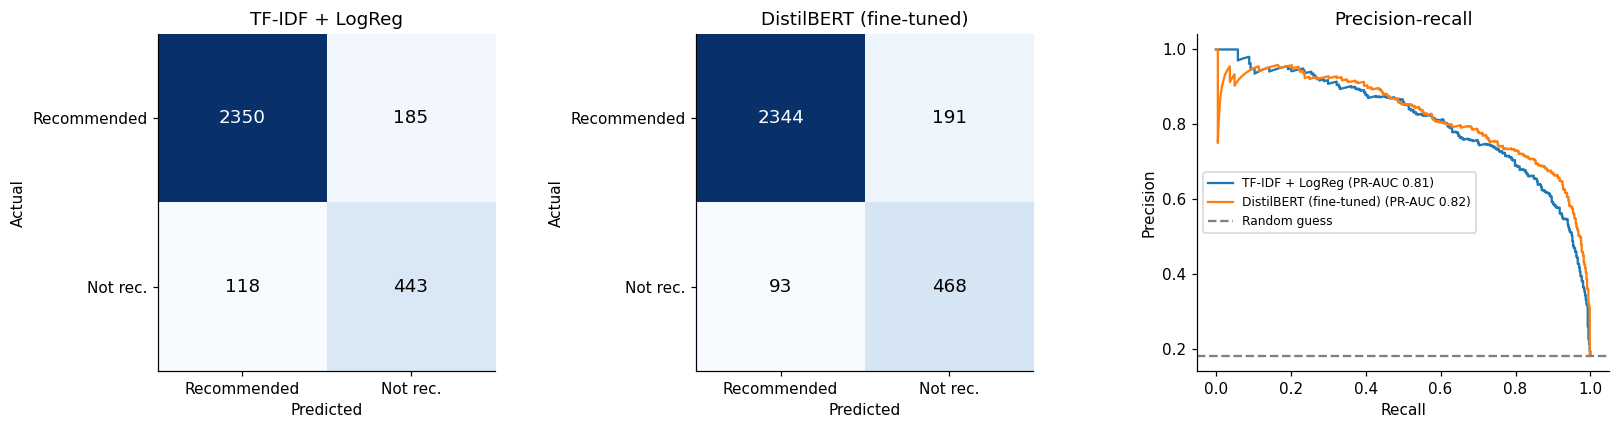

In [ ]:
fig, axes = plt.subplots(1, len(test_probs) + 1, figsize=(5 * (len(test_probs) + 1), 4))
for ax, (name, probs) in zip(axes, test_probs.items()):
    preds = (probs >= results[name]["threshold"]).astype(int)
    cm = confusion_matrix(y_test, preds)
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v}", ha="center", va="center", color="white" if v > cm.max() / 2 else "black", fontsize=12)
    ax.set_xticks([0, 1], ["Recommended", "Not rec."]); ax.set_yticks([0, 1], ["Recommended", "Not rec."])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(name)

for name, probs in test_probs.items():
    p, r, _ = precision_recall_curve(y_test, probs)
    axes[-1].plot(r, p, label=f"{name} (PR-AUC {results[name]['pr_auc']:.2f})")
axes[-1].axhline(y_test.mean(), ls="--", color="grey", label="Random guess")
axes[-1].set_xlabel("Recall"); axes[-1].set_ylabel("Precision"); axes[-1].set_title("Precision-recall"); axes[-1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/comparison.png", bbox_inches="tight"); plt.show()

## 9. Error analysis

Where does the best model go wrong? The reviews it was *most confident* about but got wrong usually reveal what's hard about the task (mixed feelings, sarcasm, sizing complaints from people who still liked the item).

In [ ]:
best_name = max(results, key=lambda n: results[n]["pr_auc"])
analysis = test_df[["review_text", "department_name", "rating"]].copy()
analysis["actual"] = y_test
analysis["prob_not_rec"] = test_probs[best_name]
analysis["pred"] = (analysis["prob_not_rec"] >= results[best_name]["threshold"]).astype(int)
wrong = analysis[analysis["pred"] != analysis["actual"]].copy()
wrong["confidence"] = (wrong["prob_not_rec"] - 0.5).abs()
pd.set_option("display.max_colwidth", 300)
print(f"Best model by PR-AUC: {best_name}. Most confident mistakes:")
wrong.sort_values("confidence", ascending=False).head(8)[["review_text", "actual", "prob_not_rec", "rating"]]

Best model by PR-AUC: DistilBERT (fine-tuned). Most confident mistakes:


,review_text,actual,prob_not_rec,rating
12082,This shirt is like the best worn in flannel with a little feminine flair! super soft and great length.,1,0.005427,5
5052,This jacket is high quality leather and will bring you years of wear! i made sure to add a little room to accommodate thick sweaters!,1,0.009634,5
7733,"This dress is beautiful, but not made for someone with a 36d. i ordered a 12 and i could get my chest in this dress. i really wish it fit. it's well made and very beautiful. belt does not come with the dress.",1,0.010091,4
7649,"I've wondered abt this swtr but hesitated to order being it has dolman sleeves. decided to wait for it to come in at the local store. yesterday i spotted it in the store & tried on the orange, labeled 'red' online. i was really looking for the 'cream' but the store did not have it. well, the ora...",1,0.012289,5
17809,Nice dress to wear while seasons are transitioning,1,0.012504,3
20065,"While the dress is pretty, it's a lot more boring than it seems online. the box top is actually a completely separate piece, which is kind of neat - you can choose to remove it or not. the box top is very wide (much wider than on the model) and very unflattering! also, the dress is a stiff silk ...",0,0.987129,3
20074,"As another reviewer pointed out, although the tag inside the dress says that you can machine wash in cold water, the color around the popsicles will bleed! this is extremely disappointing. i'm hoping it can either be fixed with dye remover, or that retailer will take this item back. would only d...",0,0.985882,2
14515,The idea of this shirt is awesome! it just needs to be made longer and not so boxy. the ruffle is darling! i would be so happy if the the designer made some modifications. i think a lot of people would buy it then.,1,0.014392,2


In [ ]:
per_dept = (analysis.groupby("department_name")
            .apply(lambda g: pd.Series({"reviews": len(g),
                                        "share_not_rec": g["actual"].mean(),
                                        "f1": f1_score(g["actual"], g["pred"], zero_division=0)}))
            .sort_values("reviews", ascending=False))
per_dept.round(3)

/tmp/ipykernel_667/2119008780.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series({"reviews": len(g),


,reviews,share_not_rec,f1
department_name,,,
Tops,1348.0,0.196,0.785
Dresses,863.0,0.183,0.745
Bottoms,530.0,0.155,0.750
Intimate,219.0,0.132,0.742
Jackets,114.0,0.202,0.816
Trend,22.0,0.227,0.769


## 10. Findings

- **Best model:** fine-tuned DistilBERT, with F1 0.767 and PR-AUC 0.824 on the not-recommended class, against 0.745 and 0.810 for the TF-IDF baseline.
- **Was fine-tuning worth it?** It gained about 2 F1 points, mostly from recall (0.790 → 0.834), so it catches about 25 more unhappy shoppers in the test set, after a few minutes of training on a free T4 GPU. The simple baseline gets most of the way there.
- **Zero-shot:** with no training at all, BART-MNLI reached F1 0.680 on a 500-review sample (baseline 0.698, DistilBERT 0.756). It had the highest precision (0.725) but missed more unhappy shoppers (recall 0.641).
- **Where it struggles:** label noise (five-star rave reviews marked "not recommended"), shoppers who complain but still recommend, and polite criticism.
- **Department differences:** Trend has the highest share of unhappy shoppers, but it's the smallest department, so that figure is less reliable.

## What I'd do next

- Clean noisy labels (e.g. five-star reviews marked "not recommended") and re-measure
- Try a larger model (e.g. RoBERTa) and longer `MAX_LEN`, and check whether the gain is worth the cost
- Calibrate probabilities so a score of 0.8 really means 80% likely
- Group flagged reviews by theme (sizing, fabric, colour) so the merchandising team gets actionable summaries
- Wrap the best model in a small Flask API so a dashboard can score new reviews